# Phase 3 — Heterogeneous Graph Construction

## Objectives

- Construct User–Movie–Genre heterogeneous graphs.
- Create Train and Train+Validation snapshots.
- Add reverse edges for message passing.
- Validate graph integrity and temporal isolation.
- Save graph artifacts for downstream GNN training.

**Environment:** Windows 11 / VS Code / Local Python `.venv`.

**Framework:** PyTorch Geometric.

**Scope:** Graph construction only; no model training.

Import và thiết lập đường dẫn

In [2]:
from pathlib import Path
import sys
import json

import pandas as pd
import torch
import torch_geometric
import matplotlib.pyplot as plt

def find_project_root():
    current = Path.cwd().resolve()

    for candidate in [current, *current.parents]:
        if (
            (candidate / "src" / "data").is_dir()
            and (candidate / "data" / "splits").is_dir()
        ):
            return candidate

    raise FileNotFoundError(
        "Project root not found"
    )

PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_ROOT = PROJECT_ROOT / "data"
GRAPH_DIR = DATA_ROOT / "graphs"

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("PyG:", torch_geometric.__version__)
print("Project:", PROJECT_ROOT)

e:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
e:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Python: e:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\.venv\Scripts\python.exe
PyTorch: 2.15.0+cpu
PyG: 2.8.1
Project: E:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender


Chạy Graph Pipeline

In [3]:
from src.data.graph_builder import run_graph_pipeline

metadata = run_graph_pipeline(DATA_ROOT)

print("Graph construction: PASSED")

display(
    pd.DataFrame(
        metadata.items(),
        columns=["Property", "Value"]
    )
)

Graph construction: PASSED


,Property,Value
0,phase,3
1,graph_type,heterogeneous
2,node_types,"[user, movie, genre]"
3,edge_types,"[[user, rates, movie], [movie, rev_rates, user..."
4,num_users,610
5,num_movies,9742
6,num_genres,19
7,train_positive_edges,39255
8,train_val_positive_edges,44452
9,movie_genre_edges,22050


Đọc hai graph snapshot

In [4]:
train_graph = torch.load(
    GRAPH_DIR / "train_graph.pt",
    map_location="cpu",
    weights_only=False,
)

train_val_graph = torch.load(
    GRAPH_DIR / "train_val_graph.pt",
    map_location="cpu",
    weights_only=False,
)

print("TRAIN GRAPH")
print(train_graph)

print("\nTRAIN + VALIDATION GRAPH")
print(train_val_graph)

TRAIN GRAPH
HeteroData(
  user={ num_nodes=610 },
  movie={ num_nodes=9742 },
  genre={ num_nodes=19 },
  (user, rates, movie)={ edge_index=[2, 39255] },
  (movie, rev_rates, user)={ edge_index=[2, 39255] },
  (movie, has_genre, genre)={ edge_index=[2, 22050] },
  (genre, rev_has_genre, movie)={ edge_index=[2, 22050] }
)

TRAIN + VALIDATION GRAPH
HeteroData(
  user={ num_nodes=610 },
  movie={ num_nodes=9742 },
  genre={ num_nodes=19 },
  (user, rates, movie)={ edge_index=[2, 44452] },
  (movie, rev_rates, user)={ edge_index=[2, 44452] },
  (movie, has_genre, genre)={ edge_index=[2, 22050] },
  (genre, rev_has_genre, movie)={ edge_index=[2, 22050] }
)


Thống kê node và edge

In [5]:
node_summary = pd.DataFrame([
    {
        "Node Type": node_type,
        "Count": train_graph[node_type].num_nodes
    }
    for node_type in train_graph.node_types
])

edge_summary = pd.DataFrame([
    {
        "Edge Type": " → ".join(edge_type),
        "Train": train_graph[
            edge_type
        ].edge_index.shape[1],
        "Train + Val": train_val_graph[
            edge_type
        ].edge_index.shape[1],
    }
    for edge_type in train_graph.edge_types
])

display(node_summary)
display(edge_summary)

,Node Type,Count
0,user,610
1,movie,9742
2,genre,19


,Edge Type,Train,Train + Val
0,user → rates → movie,39255,44452
1,movie → rev_rates → user,39255,44452
2,movie → has_genre → genre,22050,22050
3,genre → rev_has_genre → movie,22050,22050


Biểu đồ so sánh số lượng cạnh

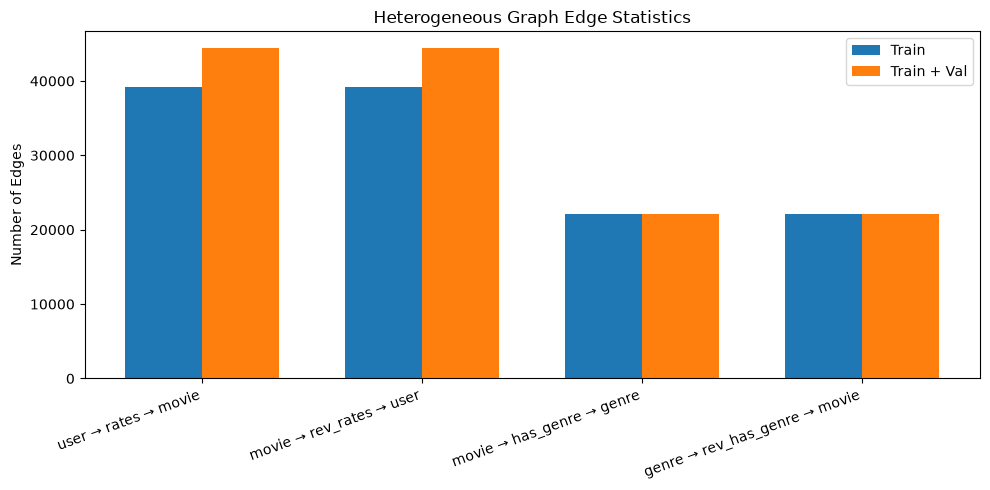

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))

x = range(len(edge_summary))
width = 0.35

ax.bar(
    [i - width / 2 for i in x],
    edge_summary["Train"],
    width,
    label="Train"
)

ax.bar(
    [i + width / 2 for i in x],
    edge_summary["Train + Val"],
    width,
    label="Train + Val"
)

ax.set_xticks(list(x))
ax.set_xticklabels(
    edge_summary["Edge Type"],
    rotation=20,
    ha="right"
)

ax.set_title("Heterogeneous Graph Edge Statistics")
ax.set_ylabel("Number of Edges")
ax.legend()

plt.tight_layout()
plt.show()

Kiểm tra graph integrity

In [7]:
from src.data.graph_builder import (
    validate_graph,
    validate_snapshot_integrity,
)

train = pd.read_csv(
    DATA_ROOT / "splits" / "train.csv"
)

train_val = pd.read_csv(
    DATA_ROOT / "splits" / "train_val.csv"
)

validate_graph(train_graph)
validate_graph(train_val_graph)

validate_snapshot_integrity(
    train_graph,
    train_val_graph,
    train,
    train_val,
)

print("Graph structure: PASSED")
print("Reverse edge consistency: PASSED")
print("Snapshot integrity: PASSED")

Graph structure: PASSED
Reverse edge consistency: PASSED
Snapshot integrity: PASSED


Kiểm tra Test không xuất hiện trong graph

In [8]:
from src.data.graph_builder import RATES, edge_pairs

test = pd.read_csv(
    DATA_ROOT / "splits" / "test.csv"
)

test_pairs = set(
    map(
        tuple,
        test[["user_idx", "movie_idx"]]
        .to_numpy().tolist(),
    )
)

train_pairs = edge_pairs(train_graph, RATES)
train_val_pairs = edge_pairs(train_val_graph, RATES)

assert train_pairs.isdisjoint(test_pairs)
assert train_val_pairs.isdisjoint(test_pairs)

print("Test interactions excluded: PASSED")

Test interactions excluded: PASSED


Chạy Unit Tests

In [9]:
import subprocess

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "unittest",
        "discover",
        "-s",
        "tests",
        "-p",
        "test_graph_builder.py",
        "-v",
    ],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True,
)

print(result.stdout)
print(result.stderr)

assert result.returncode == 0

print("Phase 3 unit tests: PASSED")


e:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
test_edge_types (test_graph_builder.TestGraphBuilder.test_edge_types) ... ok
test_graph_validation (test_graph_builder.TestGraphBuilder.test_graph_validation) ... ok
test_movie_genre_edges (test_graph_builder.TestGraphBuilder.test_movie_genre_edges) ... ok
test_no_node_features (test_graph_builder.TestGraphBuilder.test_no_node_features) ... ok
test_node_counts (test_graph_builder.TestGraphBuilder.test_node_counts) ... ok
test_node_types (test_graph_builder.TestGraphBuilder.test_node_types) ... ok
test_positive_edges_only (test_graph_builder.TestGraphBuilder.test_positive_edges_only) ... ok
test_reverse_edges (test_graph_builder.TestGraphBuilder.test_reverse_edges) ... ok
test_snapshot_integrity (test_graph_builder.TestGraphBuilder.test_snapshot_integrity) ... ok

-------

Lưu báo cáo

In [10]:
REPORT_DIR = PROJECT_ROOT / "experiments" / "phase3"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

report = {
    "phase": 3,
    "execution": "local",
    "graph_type": "heterogeneous",
    "num_node_types": len(train_graph.node_types),
    "num_edge_types": len(train_graph.edge_types),
    "num_nodes": {
        node_type: train_graph[node_type].num_nodes
        for node_type in train_graph.node_types
    },
    "train_positive_edges": int(
        train_graph[RATES].edge_index.shape[1]
    ),
    "train_val_positive_edges": int(
        train_val_graph[RATES].edge_index.shape[1]
    ),
    "graph_validation": "passed",
    "snapshot_integrity": "passed",
    "test_isolation": "passed",
    "unit_tests": "passed",
}

report_path = REPORT_DIR / "phase3_report.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(
        report,
        f,
        indent=2,
        ensure_ascii=False,
    )

print("Report saved:", report_path)

Report saved: E:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\experiments\phase3\phase3_report.json
